# 02 — Entrenamiento y optimización

XGBoost con validación estratificada sobre el train (step <= 400), optimización de hiperparámetros con Optuna y registro de los experimentos en DagsHub (MLflow).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from xgboost import XGBClassifier

def leer_env(nombre):
    valor = os.environ.get(nombre)
    if valor:
        return valor
    import winreg
    with winreg.OpenKey(winreg.HKEY_CURRENT_USER, r"Environment") as clave:
        valor, _ = winreg.QueryValueEx(clave, nombre)
        return valor


SEED = 42
TARGET = "isFraud"
N_FOLDS_MODELO = 2  # uso los folds 0 y 1 del preprocesamiento
N_TRIALS = 6

BASE = Path.cwd()
for candidato in [BASE, *BASE.parents]:
    if (candidato / "Datos" / "procesado" / "train.parquet").exists():
        RUTA_BASE = candidato
        break
else:
    raise FileNotFoundError("No encontré Datos/procesado/. Corre primero el notebook 01.")

RUTA_PROC = RUTA_BASE / "Datos" / "procesado"
RUTA_MODELOS = RUTA_BASE / "modelos"

train = pd.read_parquet(RUTA_PROC / "train.parquet")
prod = pd.read_parquet(RUTA_PROC / "prod.parquet")
FEATURES = json.loads((RUTA_PROC / "resumen_preprocesamiento.json").read_text(encoding="utf-8"))["features"]

X_train, y_train = train[FEATURES], train[TARGET]
X_prod, y_prod = prod[FEATURES], prod[TARGET]
print(f"Train: {X_train.shape} | fraude {100 * y_train.mean():.4f}%")
print(f"Prod:  {X_prod.shape} | fraude {100 * y_prod.mean():.4f}%")

D:\DSRP-ML3-Proyecto-Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/18 23:43:52 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at D:\DSRP-ML3-Proyecto-Final\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Train: (5787030, 12) | fraude 0.0774%
Prod:  (575590, 12) | fraude 0.6491%


## Conexión con DagsHub

In [2]:
usuario = leer_env("DAGSHUB_USERNAME")
os.environ["MLFLOW_TRACKING_USERNAME"] = usuario
os.environ["MLFLOW_TRACKING_PASSWORD"] = leer_env("DAGSHUB_TOKEN")
mlflow.set_tracking_uri(f"https://dagshub.com/{usuario}/DSRP-ML3-Proyecto-Final.mlflow")
mlflow.set_experiment("fraude-paysim")
print("MLflow tracking URI:", mlflow.get_tracking_uri())

MLflow tracking URI: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow


## Métricas del problema

Precision, Recall, F1, AUC-ROC, AUC-PR y Lift (captura en el top 5% sobre el azar).

In [3]:
def calcular_metricas(y_true, y_prob, umbral=0.5):
    y_pred = (y_prob >= umbral).astype(int)
    n_top = max(1, int(0.05 * len(y_true)))
    idx_top = np.argsort(y_prob)[-n_top:]
    tasa_captura = y_true.iloc[idx_top].sum() / y_true.sum()
    return {
        "precision": float(precision_score(y_true, y_pred)),
        "recall": float(recall_score(y_true, y_pred)),
        "f1": float(f1_score(y_true, y_pred)),
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
        "pr_auc": float(average_precision_score(y_true, y_prob)),
        "lift_top5": float(tasa_captura / 0.05),
    }


def cv_folds():
    for k in range(N_FOLDS_MODELO):
        idx_val = train["fold"] == k
        yield train.loc[~idx_val], train.loc[idx_val]

## 1. Baseline

In [4]:
PARAMS_BASE = {
    "max_depth": 5,
    "learning_rate": 0.1,
    "n_estimators": 300,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": SEED,
    "eval_metric": "logloss",
}

with mlflow.start_run(run_name="baseline"):
    mlflow.log_params(PARAMS_BASE)
    filas = []
    for k, (tr, va) in enumerate(cv_folds()):
        modelo = XGBClassifier(**PARAMS_BASE, scale_pos_weight=(1 - tr[TARGET].mean()) / tr[TARGET].mean())
        modelo.fit(tr[FEATURES], tr[TARGET])
        m = calcular_metricas(va[TARGET], modelo.predict_proba(va[FEATURES])[:, 1])
        m["fold"] = k
        filas.append(m)
        print(f"fold {k}: " + " | ".join(f"{k2}={v2:.4f}" for k2, v2 in m.items() if k2 != "fold"))
    baseline_cv = pd.DataFrame(filas).drop(columns="fold")
    for col in baseline_cv.columns:
        mlflow.log_metric(f"cv_{col}_mean", float(baseline_cv[col].mean()))
        mlflow.log_metric(f"cv_{col}_std", float(baseline_cv[col].std()))

print("\nBaseline (media de3 folds):")
baseline_cv.mean().round(4).to_frame("media").join(baseline_cv.std().round(4).to_frame("std"))

fold 0: precision=0.9922 | recall=0.9922 | f1=0.9922 | roc_auc=0.9994 | pr_auc=0.9936 | lift_top5=19.9330


fold 1: precision=0.9889 | recall=0.9911 | f1=0.9900 | roc_auc=0.9994 | pr_auc=0.9930 | lift_top5=19.9777


🏃 View run baseline at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/8db5bde743d746e183638a32e4fdd1b9
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0



Baseline (media de3 folds):


,media,std
precision,0.9905,0.0024
recall,0.9916,0.0008
f1,0.9911,0.0016
roc_auc,0.9994,0.0000
pr_auc,0.9933,0.0004
lift_top5,19.9553,0.0316


## 2. Optimización con Optuna (TPE)

In [5]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 1e-2, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 250),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "tree_method": "hist",
        "random_state": SEED,
        "eval_metric": "logloss",
    }
    f1s = []
    with mlflow.start_run(run_name=f"optuna_trial_{trial.number}", nested=True):
        for k, (tr, va) in enumerate(cv_folds()):
            modelo = XGBClassifier(**params, scale_pos_weight=(1 - tr[TARGET].mean()) / tr[TARGET].mean())
            modelo.fit(tr[FEATURES], tr[TARGET])
            m = calcular_metricas(va[TARGET], modelo.predict_proba(va[FEATURES])[:, 1])
            f1s.append(m["f1"])
            mlflow.log_metrics({f"fold{k}_{k2}": v2 for k2, v2 in m.items()})
        mlflow.log_params(params)
    media_f1 = float(np.mean(f1s))
    trial.set_user_attr("f1_folds", f1s)
    return media_f1

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objetivo, n_trials=N_TRIALS)

print("Mejor F1 medio (CV):", round(study.best_value, 4))
pd.Series(study.best_params).to_frame("valor")

🏃 View run optuna_trial_0 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/20449d0f4cfa42858b0212c19396a9aa
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


🏃 View run optuna_trial_1 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/7549ef1226ba47d7a3e385ef196c44f9
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


🏃 View run optuna_trial_2 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/52f87a6ef0504dc3baad78b3aff4e380
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


🏃 View run optuna_trial_3 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/132626950ccf4ad4955a01595e6950be
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


🏃 View run optuna_trial_4 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/c807b433bf2643449ae6470b575be29c
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


🏃 View run optuna_trial_5 at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/08c1674dc29949cc8af0019b08bbac1a
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


Mejor F1 medio (CV): 0.9922


,valor
max_depth,4.000000
learning_rate,0.018660
n_estimators,145.000000
min_child_weight,6.000000
subsample,0.772778
colsample_bytree,0.716492
reg_lambda,0.280164


## 3. Mejor modelo: entrenamiento final y evaluación online

Entreno con todo el train y evalúo en el periodo de producción (step >= 401).

,offline_train,online_produccion
precision,0.9942,1.0000
recall,0.9931,0.9995
f1,0.9936,0.9997
roc_auc,0.9998,1.0000
pr_auc,0.9958,0.9997
lift_top5,19.9777,20.0000


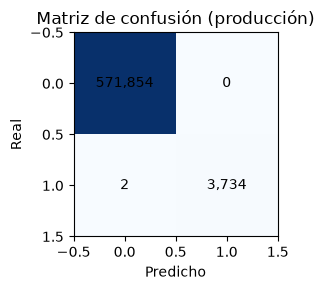

In [6]:
mejores_params = {**study.best_params, **{
    "tree_method": "hist", "random_state": SEED, "eval_metric": "logloss"
}}

modelo_final = XGBClassifier(
    **mejores_params,
    scale_pos_weight=(1 - y_train.mean()) / y_train.mean(),
)
modelo_final.fit(X_train, y_train)

metricas_offline = calcular_metricas(y_train, modelo_final.predict_proba(X_train)[:, 1])
metricas_online = calcular_metricas(y_prod, modelo_final.predict_proba(X_prod)[:, 1])

tabla_metricas = pd.DataFrame({"offline_train": metricas_offline, "online_produccion": metricas_online}).round(4)

cm = confusion_matrix(y_prod, (modelo_final.predict_proba(X_prod)[:, 1] >= 0.5).astype(int))
fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="black")
ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (producción)")
fig.tight_layout()

modelo_final.get_booster().save_model(str(RUTA_MODELOS / "modelo_xgb.json"))
fig.savefig(RUTA_MODELOS / "matriz_confusion_prod.png", dpi=120)

tabla_metricas

In [7]:
with mlflow.start_run(run_name="modelo_final_optimizado"):
    mlflow.log_params(mejores_params)
    mlflow.log_metrics({f"offline_{k}": v for k, v in metricas_offline.items()})
    mlflow.log_metrics({f"online_{k}": v for k, v in metricas_online.items()})
    mlflow.log_artifact(str(RUTA_MODELOS / "modelo_xgb.json"))
    mlflow.log_artifact(str(RUTA_MODELOS / "matriz_confusion_prod.png"))

(RUTA_MODELOS / "metricas.json").write_text(
    json.dumps(
        {"mejores_params": mejores_params, "offline": metricas_offline, "online": metricas_online},
        indent=2,
    ),
    encoding="utf-8",
)

importancia = pd.Series(modelo_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("Importancia de features (gain):")
print(importancia.round(4).to_string())
print("\nExperimento registrado en DagsHub:", mlflow.get_tracking_uri())

🏃 View run modelo_final_optimizado at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0/runs/3b042351239647f9bb3c951146a65d3e
🧪 View experiment at: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow/#/experiments/0


Importancia de features (gain):
errorBalanceOrig    0.3930
ratio_amount        0.3471
newbalanceOrig      0.1655
isMerchant          0.0438
oldbalanceOrg       0.0133
amount              0.0086
errorBalanceDest    0.0074
isTransfer          0.0063
oldbalanceDest      0.0048
isCashOut           0.0046
newbalanceDest      0.0038
step                0.0018

Experimento registrado en DagsHub: https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final.mlflow


## Análisis

- **Baseline** (XGBoost con parámetros fijos, CV estratificada de 2 folds): F1 0.9911, AUC-ROC 0.9994, AUC-PR 0.9933 y lift de casi 20 (en el 5% más puntuado hay ~20 veces más fraude que el azar). Ya parto de un punto alto.
- **Optuna (TPE, 6 trials)** mejoró el F1 a 0.9922. Los ganadores: `max_depth=4`, `learning_rate=0.0187`, `n_estimators=145`, `min_child_weight=6`, `subsample=0.77`, `colsample_bytree=0.72`, `reg_lambda=0.28`. La mejora es chica porque en PaySim las variables de saldo delatan el fraude casi sin esfuerzo.
- **Modelo final reentrenado con todo el train**: offline F1 0.9936 y online (step >= 401) precision 1.0000, recall 0.9995, F1 0.9997, AUC-ROC 1.0000. No hay caída en producción; de hecho las métricas suben porque el período de producción tiene más fraude por fila (0.6491% vs 0.0774%).
- La importancia por gain la concentran `errorBalanceOrig` (39%) y `ratio_amount` (35%), que son justamente las variables creadas en el notebook 01: sin el ingenio de features este modelo no existiría.
- **DagsHub**: 8 runs (baseline + 6 trials + modelo final) con params, métricas y artefactos (modelo, matriz de confusión PNG y métricas JSON): https://dagshub.com/kin-ordaya/DSRP-ML3-Proyecto-Final